# Stage 2 — Phase segmentation (heuristic)

**Pipeline stage 2 of 5**: patient-level split → **phase segmentation** → train + explain →
candidate discovery → confirm & report.

Finds S1 / systole / S2 / diastole boundaries for every cardiac cycle in every **development-set**
recording (confirmation-set recordings are intentionally left untouched — locked until Stage 5).
This is what makes "late systole" or "early diastole" answerable later in Stage 4, rather than
only a raw time-frame index.

## Method (simple heuristic, no training data required)

1. **Shannon energy envelope** — emphasises the two loud heart-sound bursts (S1, S2) per cycle
   relative to the quieter systolic/diastolic background.
2. **Peak detection** on that envelope, with a minimum-spacing and prominence threshold tuned
   to reject spurious sub-peaks (murmur texture, noise) while keeping true S1/S2 bursts.
3. **S1/S2 labeling** by the standard heuristic: systole (S1→S2) is shorter and more fixed in
   duration than diastole (S2→S1) across most heart rates, so the shorter of the two alternating
   inter-peak interval sets tells us which peaks are S1 and which are S2.
4. **Boundary + sub-phase construction** — a short window around each S1/S2 peak, and the gap
   between consecutive sounds split into `early` / `mid` / `late` thirds, so a claim like "late
   systole" is directly expressible rather than approximated.
5. **Per-recording quality metrics** — implied heart rate and cycle-length consistency, flagged
   `ok` / `low_confidence_*` / `failed_*` so later stages can exclude or down-weight
   unreliable segmentations rather than trusting every recording equally.

**This is deliberately the simple baseline.** The CUED reference repo's HSMM segmenter is the
planned alternative — same output shape (phase boundaries per recording), different method —
so Stage 4 can compare candidate markers found under either and report whether they agree.
Both save to sibling folders under `artifacts/02_segmentation/`, this notebook writes to
`artifacts/02_segmentation/heuristic/`.

All of the actual segmentation logic lives in `pipeline_common/segmentation.py` (shared code,
not copy-pasted here), so Stage 5's later re-run on the confirmation set uses the identical
function, not a re-implementation that could silently drift.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ---- Setup ----------------------------------------------------------------
import sys
import json
import datetime
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

package_path = "/content/drive/MyDrive/Research 2026/mi_marker_pipeline"
if package_path not in sys.path:
    sys.path.insert(0, package_path)
from pipeline_common import config
from pipeline_common.audio import load_and_resample, pad_or_trim
from pipeline_common.segmentation import segment_recording_heuristic

import random
random.seed(config.SEED); np.random.seed(config.SEED)

PREV_STAGE_DIR = config.ARTIFACTS_DIR / "01_split"
STAGE_DIR = config.ARTIFACTS_DIR / "02_segmentation" / "heuristic"
STAGE_DIR.mkdir(parents=True, exist_ok=True)

print("Reading Stage 1 output from:", PREV_STAGE_DIR)
print("Saving this stage's output to:", STAGE_DIR)

Reading Stage 1 output from: /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/01_split
Saving this stage's output to: /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/02_segmentation/heuristic


## 1. Load Stage 1's split, keep development-set recordings only

Confirmation-set recordings are deliberately excluded here — they get segmented for the first
and only time in Stage 5, using this same code.

In [4]:
metadata = pd.read_csv(PREV_STAGE_DIR / "metadata_with_split.csv")
dev_metadata = metadata[metadata["split"] == "development"].reset_index(drop=True)

print(f"{len(metadata)} total recordings ({metadata['patient_id'].nunique()} patients)")
print(f"{len(dev_metadata)} development recordings "
      f"({dev_metadata['patient_id'].nunique()} patients) -- these are what this stage processes")
print(f"{len(metadata) - len(dev_metadata)} confirmation recordings -- left untouched until Stage 5")
dev_metadata.head()

3360 total recordings (140 patients)
2688 development recordings (112 patients) -- these are what this stage processes
672 confirmation recordings -- left untouched until Stage 5


,filepath,label,class_name,patient_id,site,segment,split
0,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,1,development
1,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,2,development
2,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,3,development
3,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,4,development
4,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,P0071,apex,5,development


## 2. Run the heuristic segmenter over every development recording

Collects two things per recording: the phase boundary rows (long format — one row per
S1/systole/S2/diastole interval, empty if segmentation failed) and a quality-metrics row
(always one row per recording, even on failure, so Stage 4 knows every recording was attempted).

In [5]:
all_boundary_rows = []
all_quality_rows = []

for i, row in dev_metadata.iterrows():
    signal = pad_or_trim(
        load_and_resample(row["filepath"], config.SAMPLE_RATE), config.SAMPLE_RATE, config.CLIP_SECONDS
    )
    boundaries, quality = segment_recording_heuristic(signal, config.SAMPLE_RATE)

    for b in boundaries:
        all_boundary_rows.append({
            "filepath": row["filepath"], "patient_id": row["patient_id"],
            "class_name": row["class_name"], "site": row["site"], "segment": row["segment"],
            **b,
        })

    all_quality_rows.append({
        "filepath": row["filepath"], "patient_id": row["patient_id"],
        "class_name": row["class_name"], "site": row["site"], "segment": row["segment"],
        **quality,
    })

    if (i + 1) % 100 == 0 or (i + 1) == len(dev_metadata):
        print(f"  segmented {i + 1}/{len(dev_metadata)} recordings")

boundaries_df = pd.DataFrame(all_boundary_rows)
quality_df = pd.DataFrame(all_quality_rows)

print(f"\n{len(boundaries_df)} phase-boundary rows across {quality_df['quality_flag'].eq('ok').sum() + quality_df['quality_flag'].str.startswith('low_confidence').sum()} successfully segmented recordings")

  segmented 100/2688 recordings
  segmented 200/2688 recordings
  segmented 300/2688 recordings
  segmented 400/2688 recordings
  segmented 500/2688 recordings
  segmented 600/2688 recordings
  segmented 700/2688 recordings
  segmented 800/2688 recordings
  segmented 900/2688 recordings
  segmented 1000/2688 recordings
  segmented 1100/2688 recordings
  segmented 1200/2688 recordings
  segmented 1300/2688 recordings
  segmented 1400/2688 recordings
  segmented 1500/2688 recordings
  segmented 1600/2688 recordings
  segmented 1700/2688 recordings
  segmented 1800/2688 recordings
  segmented 1900/2688 recordings
  segmented 2000/2688 recordings
  segmented 2100/2688 recordings
  segmented 2200/2688 recordings
  segmented 2300/2688 recordings
  segmented 2400/2688 recordings
  segmented 2500/2688 recordings
  segmented 2600/2688 recordings
  segmented 2688/2688 recordings

150640 phase-boundary rows across 2680 successfully segmented recordings


## 3. Segmentation quality summary

Sanity-check before trusting any of this downstream: does the implied heart rate distribution
look physiologically plausible, and how many recordings failed or came out low-confidence?

quality_flag  failed_too_few_cycles  failed_too_few_peaks  \
class_name                                                  
Myocardial                        2                     1   
Normal                            1                     4   

quality_flag  low_confidence_hr_out_of_range  low_confidence_irregular_cycles  \
class_name                                                                      
Myocardial                                12                               95   
Normal                                     8                               61   

quality_flag    ok  
class_name          
Myocardial    1234  
Normal        1270  


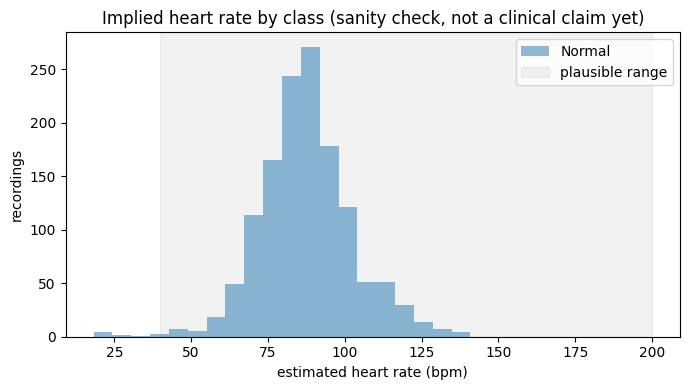


8 recordings failed to segment at all (excluded from boundaries_df)
176 recordings segmented but flagged low-confidence (present in boundaries_df, worth treating cautiously in Stage 4)

Failed recordings:
                                               filepath  class_name  \
30    /content/drive/MyDrive/Research 2026/Segmented...      Normal   
541   /content/drive/MyDrive/Research 2026/Segmented...      Normal   
588   /content/drive/MyDrive/Research 2026/Segmented...      Normal   
1152  /content/drive/MyDrive/Research 2026/Segmented...      Normal   
1299  /content/drive/MyDrive/Research 2026/Segmented...      Normal   
1360  /content/drive/MyDrive/Research 2026/Segmented...  Myocardial   
1597  /content/drive/MyDrive/Research 2026/Segmented...  Myocardial   
2486  /content/drive/MyDrive/Research 2026/Segmented...  Myocardial   

               quality_flag  
30     failed_too_few_peaks  
541    failed_too_few_peaks  
588    failed_too_few_peaks  
1152  failed_too_few_cycles  
1299

In [6]:
print(quality_df.groupby("class_name")["quality_flag"].value_counts().unstack(fill_value=0))

from pipeline_common.segmentation import MIN_HR_BPM, MAX_HR_BPM

fig, ax = plt.subplots(figsize=(7, 4))
for cls, color in zip(config.CLASSES, ["tab:blue", "tab:red"]):
    vals = quality_df.loc[quality_df["class_name"] == cls, "estimated_hr_bpm"].dropna()
    if len(vals) > 0:
        ax.hist(vals, bins=20, alpha=0.5, label=cls, color=color)
ax.axvspan(MIN_HR_BPM, MAX_HR_BPM, color="gray", alpha=0.1, label="plausible range", zorder=0)
ax.set_xlabel("estimated heart rate (bpm)"); ax.set_ylabel("recordings")
ax.set_title("Implied heart rate by class (sanity check, not a clinical claim yet)")
ax.legend()
plt.tight_layout(); plt.show()

n_failed = quality_df["quality_flag"].str.startswith("failed").sum()
n_low_conf = quality_df["quality_flag"].str.startswith("low_confidence").sum()
print(f"\n{n_failed} recordings failed to segment at all (excluded from boundaries_df)")
print(f"{n_low_conf} recordings segmented but flagged low-confidence "
      f"(present in boundaries_df, worth treating cautiously in Stage 4)")
if n_failed > 0:
    print("\nFailed recordings:")
    print(quality_df.loc[quality_df["quality_flag"].str.startswith("failed"),
                         ["filepath", "class_name", "quality_flag"]])

## 4. Visual validation

Phase boundaries shaded directly on the waveform for a few example recordings — this is the
actual gut-check for whether the heuristic is doing something sensible, not just whether the
numbers look plausible in aggregate.

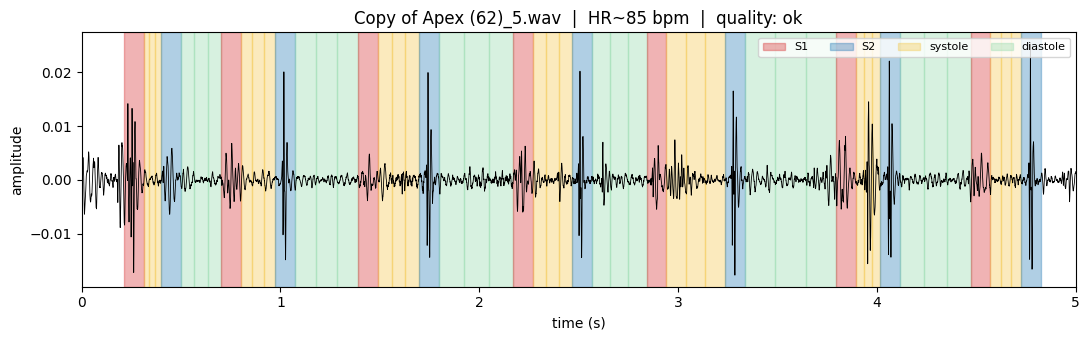

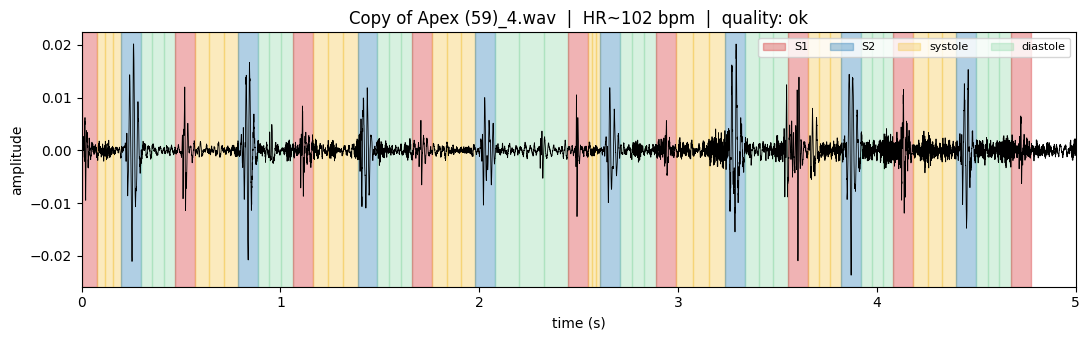

In [7]:
PHASE_COLORS = {"S1": "#d62728", "S2": "#1f77b4", "systole": "#f4c542", "diastole": "#8fd9a8"}

def plot_segmentation(filepath, sr=config.SAMPLE_RATE, seconds=config.CLIP_SECONDS):
    signal = pad_or_trim(load_and_resample(filepath, sr), sr, seconds)
    boundaries, quality = segment_recording_heuristic(signal, sr)
    t = np.arange(len(signal)) / sr

    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(t, signal, color="black", linewidth=0.6, zorder=3)
    for b in boundaries:
        ax.axvspan(b["start_time_s"], b["end_time_s"],
                  color=PHASE_COLORS.get(b["phase"], "gray"), alpha=0.35, zorder=1)
    handles = [Patch(color=c, alpha=0.35, label=p) for p, c in PHASE_COLORS.items()]
    ax.legend(handles=handles, loc="upper right", ncol=4, fontsize=8)
    ax.set_xlim(0, seconds)
    ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude")
    ax.set_title(f"{pathlib.Path(filepath).name}  |  HR~{quality['estimated_hr_bpm']:.0f} bpm  "
                 f"|  quality: {quality['quality_flag']}")
    plt.tight_layout(); plt.show()
    return boundaries, quality

# A couple of examples per class, picked at random each run (change the seed above for others)
for cls in config.CLASSES:
    examples = dev_metadata[dev_metadata["class_name"] == cls].sample(
        n=min(2, (dev_metadata["class_name"] == cls).sum()), random_state=config.SEED
    )
    for _, row in examples.iterrows():
        plot_segmentation(row["filepath"])

## 5. Save this stage's outputs

In [8]:
boundaries_df.to_csv(STAGE_DIR / "phase_boundaries.csv", index=False)
quality_df.to_csv(STAGE_DIR / "segmentation_quality.csv", index=False)

config_used = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "method": "heuristic_shannon_energy",
    "sample_rate": config.SAMPLE_RATE,
    "clip_seconds": config.CLIP_SECONDS,
    "n_development_recordings": int(len(dev_metadata)),
    "n_boundary_rows": int(len(boundaries_df)),
    "quality_flag_counts": quality_df["quality_flag"].value_counts().to_dict(),
}
with open(STAGE_DIR / "config_used.json", "w") as f:
    json.dump(config_used, f, indent=2, default=str)

print("Saved:")
print(f"  {STAGE_DIR / 'phase_boundaries.csv'}  ({len(boundaries_df)} rows)")
print(f"  {STAGE_DIR / 'segmentation_quality.csv'}  ({len(quality_df)} rows)")
print(f"  {STAGE_DIR / 'config_used.json'}")

Saved:
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/02_segmentation/heuristic/phase_boundaries.csv  (150640 rows)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/02_segmentation/heuristic/segmentation_quality.csv  (2688 rows)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/02_segmentation/heuristic/config_used.json


## Next: Stage 3

Stage 3 reads `artifacts/01_split/metadata_with_split.csv` (development recordings) and trains
the CRNN via patient-grouped k-fold CV, saving out-of-fold Grad-CAM / true-gradient
explanations for every development recording — those, combined with this stage's phase
boundaries, are what Stage 4 turns into candidate markers.

Recordings with `quality_flag` starting with `failed` won't have phase boundaries to align
explanations to; Stage 4 should either exclude them from the phase-specific analysis or treat
them as "phase unknown" rather than silently dropping them from the dataset entirely.